<a href="https://colab.research.google.com/github/nannastahl/CB2330-project/blob/main/project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Card – Amyloid-Beta Membrane Binding

**What the paper does:**  
Davis and Berkowitz (2009), *Interaction Between Amyloid-β (1–42) Peptide and Phospholipid Bilayers: A Molecular Dynamics Study.*

[Original paper and Table 4](https://pmc.ncbi.nlm.nih.gov/articles/PMC2716579/)

**The data object:**  
Binding free energies (ΔG) from Table 4, using DPPC (−16.0 kcal/mol) and DOPS (−6.6 kcal/mol) at pH 7.

**The random variable chosen:**  
The peptide's position (z), determining whether it is bound (z = 0) or unbound (z > 0).

**Paper outline:**  
Uses molecular dynamics and umbrella sampling to investigate interactions between amyloid-beta peptides and lipid membranes.

**The generative model proposed:**  
A one-dimensional Monte Carlo random walk with the Metropolis algorithm, where movement depends on the energy difference between bound and unbound states.

**Parameters and assumptions:**  
Our only fitted parameter was ε (kcal/mol), representing the effective binding energy. We assumed a fixed temperature of 323 K, pH 7, and a simplified membrane at z = 0.

**The forward simulation:**  
We simulated peptide movement and calculated ΔG from the proportion of bound and unbound states. Higher ε values made membrane escape increasingly unlikely.

**The parameterization/fitting:**  
The forward model was not sufficiently robust for reliable inference. Instead, we used an analytical expression for ΔG with ABC-MCMC to practise the backward inference workflow.

**What the model adds to the paper:**  
Our model demonstrates how binding energy influences membrane occupancy, but doesn't manage to ad any new perspective. It is clear how difficult parameter inference becomes with a simplified physical model.

**Model limitations/how it breaks:**  
The single parameter ε effectively accounts for several physical interactions. At high binding energies, the peptide can remain trapped during the simulation. A more realistic model with additional parameters would be needed for reliable inference.

When epsilon = 10 delta G = -100 kcal/mol

DOPS pH 7
Observed delta G: -6.6 kcal/mol
Acceptance rate: 0.749
Estimated epsilon: 9.558165464154651 +/- 0.28859822665153195 kcal/mol


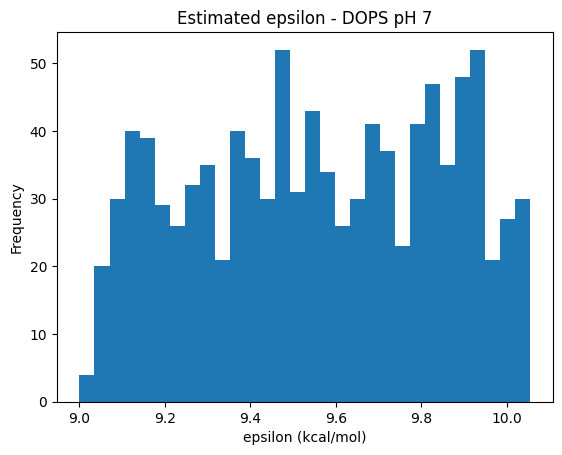


DPPC pH 7
Observed delta G: -16.0 kcal/mol
Acceptance rate: 0.766
Estimated epsilon: 18.961332128561807 +/- 0.2834414972915364 kcal/mol


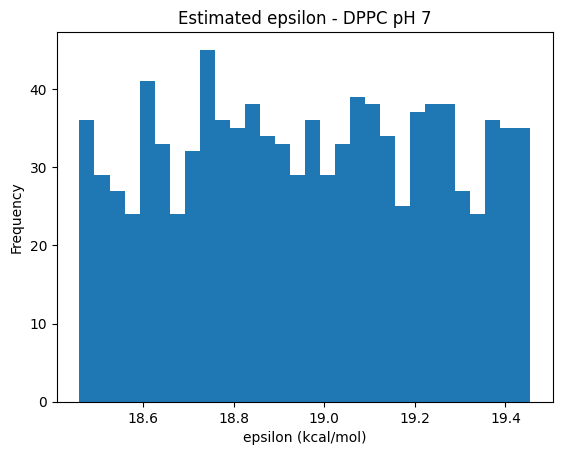

In [3]:
import matplotlib.pyplot as plt
import numpy as np

# PARAMETERS
T = 323  # temperature 323K
R = 1.987 * (10**-3)  # gas constant kcal/(mol*K)
z_max = 100  # max size of grid. z=0 is our membrane
steps = 100000  # number of steps in Monte Carlo
equilibration_steps = 10000  # steps before positions are recorded

# ASSUMPTIONS
# pH = 7 so that the output delta_G can be compared
# with the pH 7 values in Table 4
# z = 0 represents the membrane-bound state
# z > 0 represents the unbound state
# epsilon represents the effective energy difference
# between the bound and unbound state


# THE FORWARD LOOP
def forward_simulation(T, R, epsilon, steps, z_max):
  z_current = 50  # starting position
  z_pos = []  # empty list used later to store positions
  random_steps = np.random.choice([-1, 1], size=steps + equilibration_steps)

  for i in range(steps + equilibration_steps):
    dz = random_steps[i]  # random step
    z_new = z_current + dz  # new position

    # boundary checks
    if z_new < 0:
      z_new = 0  # reverts back to membrane
    elif z_new > z_max:
      z_new = z_current  # revert back to current position

    # calculation of Energy change ("delta E")
    if z_current == 1 and z_new == 0:
      # Protein moves from unbound position z=1 to the membrane at z=0.
      # Energy is lowered by epsilon.
      delta_E = -epsilon
    elif z_current == 0 and z_new == 1:
      # Protein moves away from the membrane from z=0 to z=1.
      # This costs energy epsilon.
      delta_E = +epsilon
    else:  # z_current > 0 and z_new > 0
      # Movement in the unbound region does not change the energy in this simplified model.
      delta_E = 0

    # THE METROPOLIS DECISION
    if delta_E <= 0:  # move is neutral or lowers energy
      z_current = z_new  # move accepted
    else:  # move costs energy
      P = np.exp(-(delta_E / (R * T)))
      r = np.random.uniform(0, 1)  # random number between 0 and 1
      if r < P:
        z_current = z_new

    # only record positions after equilibration
    if i >= equilibration_steps:
      z_pos.append(z_current)

  # ANALYSIS
  pos_arr = np.array(z_pos)  # turn list into array
  n_bound = np.sum(pos_arr == 0)  # calculate number of bound positions
  n_unbound = np.sum(pos_arr > 0)  # calculate number of unbound positions

  if n_bound > 0 and n_unbound > 0:
    K = n_bound / n_unbound  # calculate equilibrium ratio
    delta_G = -R * T * np.log(K)  # calculate Gibbs free energy
  elif n_bound == 0:
    delta_G = 100  # kcal/mol
  else:
    # what happens if the protein never leaves the membrane
    # but it also means epsilon was estimated extremely strongly
    delta_G = -100  # kcal/mol

  return delta_G


# Forward simulation
epsilon = 10
delta_G = forward_simulation(T, R, epsilon, steps, z_max)
print("When epsilon =", epsilon, "delta G =", delta_G, "kcal/mol")


# equilibrium delta G for the same lattice model
def equilibrium_delta_G(T, R, epsilon, z_max):
  # one bound state and z_max unbound states
  K = np.exp(epsilon / (R * T)) / z_max
  delta_G = -R * T * np.log(K)
  return delta_G


# Backward inference
PRIOR = (0.0, 30.0)


def abc_mcmc_energy(n_steps, tolerance, start, delta_G_obs, half_width=0.5):
  epsilon = start
  chain = [0.0] * n_steps
  n_acc = 0

  for t in range(n_steps):
    # propose new epsilon close to current epsilon
    prop = epsilon + np.random.uniform(-half_width, half_width)

    if PRIOR[0] <= prop <= PRIOR[1]:
      delta_G_sim = equilibrium_delta_G(T, R, prop, z_max)

      # accept if simulated delta G is close enough
      if abs(delta_G_sim - delta_G_obs) <= tolerance:
        epsilon = prop
        n_acc += 1

    chain[t] = epsilon

  return chain, n_acc


# DOPS pH 7
delta_G_obs = -6.6  # kcal/mol from Table 4

chain, n_acc = abc_mcmc_energy(
    n_steps=1000,
    tolerance=0.5,
    start=9.0,
    delta_G_obs=delta_G_obs,
    half_width=0.5,
)

if chain is not None:
  print("\nDOPS pH 7")
  print("Observed delta G:", delta_G_obs, "kcal/mol")
  print("Acceptance rate:", n_acc / len(chain))
  print("Estimated epsilon:", np.mean(chain), "+/-", np.std(chain), "kcal/mol")

  plt.hist(chain, bins=30)
  plt.xlabel("epsilon (kcal/mol)")
  plt.ylabel("Frequency")
  plt.title("Estimated epsilon - DOPS pH 7")
  plt.show()

# DPPC pH 7
delta_G_obs = -16.0  # kcal/mol from Table 4

chain_DPPC, n_acc_DPPC = abc_mcmc_energy(
    n_steps=1000,
    tolerance=0.5,
    start=19.0,
    delta_G_obs=delta_G_obs,
    half_width=0.5,
)

if chain_DPPC is not None:
  print("\nDPPC pH 7")
  print("Observed delta G:", delta_G_obs, "kcal/mol")
  print("Acceptance rate:", n_acc_DPPC / len(chain_DPPC))
  print(
      "Estimated epsilon:",
      np.mean(chain_DPPC),
      "+/-",
      np.std(chain_DPPC),
      "kcal/mol",
  )

  plt.hist(chain_DPPC, bins=30)
  plt.xlabel("epsilon (kcal/mol)")
  plt.ylabel("Frequency")
  plt.title("Estimated epsilon - DPPC pH 7")
  plt.show()